# Weather and Day Type: Station Recovery
*By Anjeli Noémi (Mimi) Flores*

**Question:** Within stations, how does recovery differ between rainy and dry days, across temperatures, and between weekdays and weekends?

**Data:** `data/processed/station_day.csv`, September 2026 station-days. Morning = 6–10 a.m., later = 10 a.m.–8 p.m. Weather is Meteostat daily data for Chicago Midway.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sd = pd.read_csv('../data/processed/station_day.csv')
deficit = sd[sd['has_morning_deficit']].copy()   # station-days that started short

print(sd.shape, deficit.shape)
sd.head()

(30383, 20) (11408, 20)


,station_id,day,later_arrivals,later_departures,morning_arrivals,morning_departures,morning_net_departures,later_net_arrivals,has_morning_deficit,recovery,full_recovery,station_name,date,weekday,day_type,temp_mean_c,temp_min_c,temp_max_c,prcp_mm,rainy
0,CHI00005,1,20,14,1,5,4,6,True,1.500000,True,Milwaukee Ave & Wabansia Ave,2026-09-01,Tuesday,Weekday,29.5,25.0,34.4,0.0,0.0
1,CHI00005,2,22,21,2,4,2,1,True,0.500000,False,Milwaukee Ave & Wabansia Ave,2026-09-02,Wednesday,Weekday,30.2,25.6,35.6,0.0,0.0
2,CHI00005,3,12,13,0,7,7,-1,True,-0.142857,False,Milwaukee Ave & Wabansia Ave,2026-09-03,Thursday,Weekday,29.0,26.1,33.3,0.0,0.0
3,CHI00005,4,30,32,2,2,0,-2,False,NaN,False,Milwaukee Ave & Wabansia Ave,2026-09-04,Friday,Weekday,29.4,25.6,33.9,0.0,0.0
4,CHI00005,5,30,35,7,2,-5,-5,False,NaN,False,Milwaukee Ave & Wabansia Ave,2026-09-05,Saturday,Weekend,25.7,22.8,28.3,0.0,0.0


## 1. Weather data check
Every station shares the same weather on a given day, so first look at the 30 days themselves.

In [9]:
days = (sd.drop_duplicates('date')
          [['date', 'weekday', 'day_type', 'temp_mean_c', 'prcp_mm', 'rainy']]
          .sort_values('date'))

print('Days:', len(days))
print('Missing values:\n', days.isna().sum())
print(days['day_type'].value_counts())
days

Days: 30
Missing values:
 date           0
weekday        0
day_type       0
temp_mean_c    0
prcp_mm        0
rainy          0
dtype: int64
day_type
Weekday      21
Weekend       8
Labor Day     1
Name: count, dtype: int64


,date,weekday,day_type,temp_mean_c,prcp_mm,rainy
0,2026-09-01,Tuesday,Weekday,29.5,0.0,0.0
1,2026-09-02,Wednesday,Weekday,30.2,0.0,0.0
2,2026-09-03,Thursday,Weekday,29.0,0.0,0.0
3,2026-09-04,Friday,Weekday,29.4,0.0,0.0
4,2026-09-05,Saturday,Weekend,25.7,0.0,0.0
5,2026-09-06,Sunday,Weekend,23.5,0.0,0.0
6,2026-09-07,Monday,Labor Day,23.0,0.0,0.0
7,2026-09-08,Tuesday,Weekday,24.3,0.0,0.0
8,2026-09-09,Wednesday,Weekday,24.2,1.0,1.0
9,2026-09-10,Thursday,Weekday,22.0,0.0,0.0


## 2. Day-level recovery
Because weather is the same for every station on a given day, each day is one observation for weather. For each day, compute the share of deficit stations that fully recovered.

In [10]:
daily = (deficit.groupby(['date', 'day_type', 'rainy', 'temp_mean_c', 'prcp_mm'])
         .agg(deficit_stations=('station_id', 'size'),
              full_recovery_rate=('full_recovery', 'mean'),
              median_recovery=('recovery', 'median'))
         .reset_index())
daily['rain'] = daily['rainy'].map({0.0: 'Dry', 1.0: 'Rainy'})

daily.sort_values('full_recovery_rate')

,date,day_type,rainy,temp_mean_c,prcp_mm,deficit_stations,full_recovery_rate,median_recovery,rain
3,2026-09-04,Weekday,0.0,29.4,0.0,363,0.269972,0.000000,Dry
11,2026-09-12,Weekend,0.0,25.2,0.0,350,0.277143,0.000000,Dry
2,2026-09-03,Weekday,0.0,29.0,0.0,436,0.302752,0.171429,Dry
25,2026-09-26,Weekend,0.0,16.0,0.0,364,0.307692,0.000000,Dry
5,2026-09-06,Weekend,0.0,23.5,0.0,372,0.314516,0.000000,Dry
17,2026-09-18,Weekday,0.0,21.0,0.0,396,0.323232,0.145833,Dry
10,2026-09-11,Weekday,0.0,22.2,0.0,402,0.325871,0.000000,Dry
24,2026-09-25,Weekday,0.0,16.4,0.0,404,0.341584,0.250000,Dry
4,2026-09-05,Weekend,0.0,25.7,0.0,319,0.344828,0.000000,Dry
1,2026-09-02,Weekday,0.0,30.2,0.0,420,0.366667,0.500000,Dry


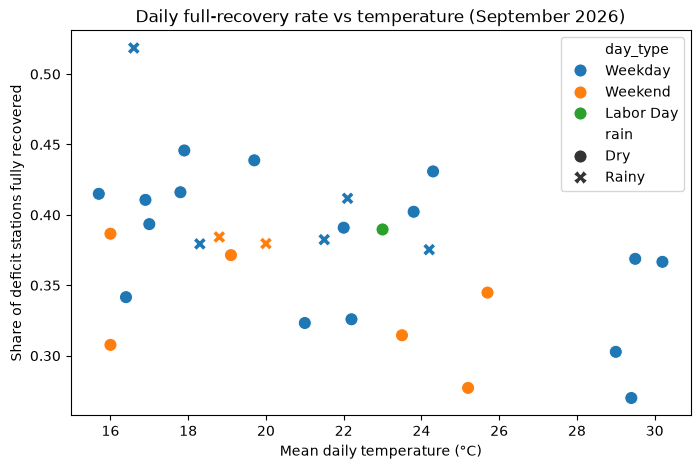

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=daily, x='temp_mean_c', y='full_recovery_rate',
                hue='day_type', style='rain', s=90, ax=ax)
ax.set(title='Daily full-recovery rate vs temperature (September 2026)',
       xlabel='Mean daily temperature (°C)',
       ylabel='Share of deficit stations fully recovered')
plt.savefig('../figures/mimi_daily_recovery_temp.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
daily.groupby(['day_type', 'rain']).agg(
    days=('date', 'size'),
    mean_daily_rate=('full_recovery_rate', 'mean'),
    min_rate=('full_recovery_rate', 'min'),
    max_rate=('full_recovery_rate', 'max')).round(3)

days  mean_daily_rate  min_rate  max_rate
day_type  rain                                            
Labor Day Dry       1            0.390     0.390     0.390
Weekday   Dry      16            0.378     0.270     0.446
          Rainy     5            0.413     0.375     0.519
Weekend   Dry       6            0.334     0.277     0.387
          Rainy     2            0.382     0.380     0.384